# 06 – Train / test workflow (first model output)

**Question.** Can Sentinel-2 features of the drought year (2017 baseline + 2018) predict which canopy units show a marked canopy decline one year later (2019), and does a model trained in one region (Fricktal, AG) transfer to the target region (Ajoie, JU) and to a different environment (Rhone valley, VS)?

## Design
| Stage | Choice | Reason |
|---|---|---|
| Training area | Fricktal / Tafeljura (AG) | comparable beech-dominated Jura forest; train elsewhere, test in the Ajoie |
| Validation | **spatial block CV** (2 km blocks, 5 folds) | random CV is over-optimistic with spatially autocorrelated data (Roberts et al. 2017; Ploton et al. 2020); the course asks for region-, scene- or buffer-based splits (L04, L07) |
| Reference | random 70/30 split | mirrors the STDL HETRES setup (Random Forest, 70/30; up to 79 % accuracy) and shows the optimism |
| Models | majority-class dummy, **ΔNDVI-2018 threshold rule** (simple baseline), Random Forest classifier, Random Forest regressor on the ordinal class | Breiman (2001); a simpler baseline as comparison; the ordinal variant respects the class order |
| Test | Ajoie (out-of-region), Rhone valley (domain shift) | never used for fitting or tuning |
| Applicability | simplified dissimilarity index / area of applicability | Meyer & Pebesma (2021) |

## Labels – read this first
**Field labels are not available.** The HETRES ground truth (226 beeches: 76 healthy, 77 unhealthy, 73 dead) is not public: the STDL repository contains code only and the documentation lists the ground truth as property of the Canton of Jura (checked 14 Nov 2026). If a file `data/labels/<aoi>_labels.gpkg` (points or polygons, column `damage_class` ∈ {0, 1, 2}) is added later, this notebook uses it automatically.

**Fallback used here: a decline proxy.** The class is derived from the measured NDVI change of the *following* year (late-summer 2019 vs 2017), standardised per AOI with a robust z-score:

| class | name | rule |
|---|---|---|
| 0 | stable | z > −1.5 |
| 1 | decline | −3 < z ≤ −1.5 |
| 2 | strong decline | z ≤ −3 |

To keep the task from being circular, the model only sees features from **2017 and 2018** plus terrain; everything from 2019 onwards is removed. So the model answers an early-warning question (does the drought-year signal anticipate next-year decline?). **The proxy is not a health label**: a low 2019 NDVI can also come from harvesting, storm damage, bark-beetle salvage or residual cloud. The metrics below measure agreement with the proxy, not accuracy against forester assessments.

In [1]:
import sys, json, re, warnings
from pathlib import Path
sys.path.append(str(Path("..").resolve() / "scripts"))   # folder containing sds_utils.py

import numpy as np, pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict, train_test_split, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, cohen_kappa_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance
import sds_utils as su
warnings.filterwarnings("ignore")

SEED = 42
TRAIN_AOI, TEST_AOIS = "fricktal_ag", ["ajoie_ju", "valais_rhone"]
BLOCK = 2000                     # m, spatial block size for CV
N_TRAIN_MAX = 40000              # units sampled from the training AOI (keeps CV + tuning to minutes)
FEATURE_YEARS = (2017, 2018)     # proxy mode: only pre-target years are allowed as features
TARGET = "dNDVI_late_2019_mean"  # proxy mode: NDVI change late 2019 vs late 2017
Z_DECLINE, Z_STRONG = -1.5, -3.0

## 1 · Load unit tables and labels

In [2]:
feat = {a: pd.read_csv(su.PROC / f"features_{a}.csv.gz", index_col="unit_id") for a in su.AOIS}
units = {a: gpd.read_file(su.PROC / f"{a}_canopy_units.gpkg") for a in su.AOIS}

def field_labels(aoi):
    p = su.LABELS / f"{aoi}_labels.gpkg"
    if not p.exists(): return None
    lab = gpd.read_file(p).to_crs(su.CRS_UTM)[["damage_class", "geometry"]]
    j = gpd.sjoin(lab, units[aoi][["unit_id", "geometry"]], predicate="intersects", how="inner")
    return j.groupby("unit_id")["damage_class"].agg(lambda s: s.mode().iloc[0]).astype(int)

def robust_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return (s - med) / (1.4826 * mad + 1e-9)

def z_classes(z):
    y = pd.Series(0, index=z.index); y[z <= Z_DECLINE] = 1; y[z <= Z_STRONG] = 2
    return y

field = {a: field_labels(a) for a in su.AOIS}
LABEL_SOURCE = "field" if field[TRAIN_AOI] is not None else "proxy"
CLASSES = ({0: "healthy", 1: "unhealthy", 2: "dead"} if LABEL_SOURCE == "field"
           else {0: "stable", 1: "decline", 2: "strong decline"})
print("label source:", LABEL_SOURCE.upper())
if LABEL_SOURCE == "proxy":
    print("NOTE: proxy = robust z-score of", TARGET, "per AOI. Metrics = agreement with the proxy, not field accuracy.")

frames = []
for a in su.AOIS:
    df = feat[a].copy()
    if LABEL_SOURCE == "field":
        if field[a] is None: print(f"  no labels for {a} -> excluded from evaluation"); continue
        df = df.join(field[a].rename("dmg"), how="inner")
    else:
        df = df[df[TARGET].notna()]
        df["dmg"] = z_classes(robust_z(df[TARGET]))
        df["rule_2018"] = z_classes(robust_z(df["dNDVI_late_2018_mean"].fillna(df["dNDVI_late_2018_mean"].median())))
    df["aoi"] = a; df["unit_id"] = df.index; frames.append(df)
data = pd.concat(frames, ignore_index=True)

META = {"dmg", "rule_2018", "aoi", "unit_id", "x", "y", "n_pix"}   # x, y = unit centroid (blocking only)
def feature_year(c):
    m = re.search(r"_(20\d\d)_", c); return int(m.group(1)) if m else None
FEATURES = [c for c in data.columns if c not in META]
if LABEL_SOURCE == "proxy":      # early-warning setup: nothing from the target year or later
    FEATURES = [c for c in FEATURES if feature_year(c) is None or feature_year(c) in FEATURE_YEARS]
print(len(FEATURES), "features, e.g.", FEATURES[:4], "...")
counts = data.groupby("aoi")["dmg"].value_counts().unstack(fill_value=0).rename(columns=CLASSES)
counts["share_not_stable_%"] = (100 * (1 - counts.iloc[:, 0] / counts.sum(axis=1))).round(1)
counts

label source: PROXY
NOTE: proxy = robust z-score of dNDVI_late_2019_mean per AOI. Metrics = agreement with the proxy, not field accuracy.
38 features, e.g. ['NDVI_peak_2017_mean', 'NDRE_peak_2017_mean', 'NDMI_peak_2017_mean', 'NBR_peak_2017_mean'] ...


dmg,stable,decline,strong decline,share_not_stable_%
aoi,,,,
ajoie_ju,28649,2670,804,10.8
fricktal_ag,27031,1763,551,7.9
valais_rhone,35948,2375,598,7.6


## 2 · Split: spatial blocks inside the training AOI

29345 training units in 55 blocks


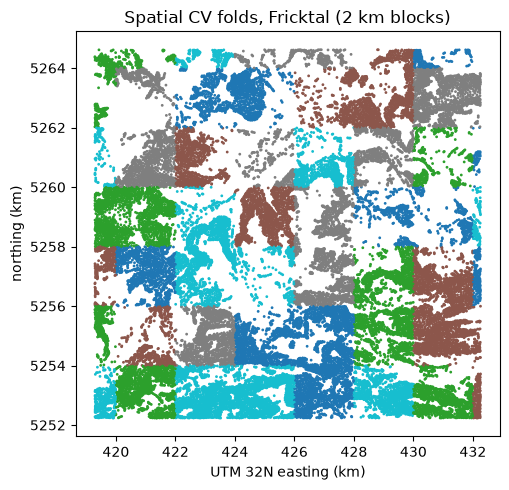

In [3]:
tr = data[data.aoi == TRAIN_AOI]
tr = tr.sample(n=min(N_TRAIN_MAX, len(tr)), random_state=SEED)
tr_idx = tr.index                      # row labels in `data`, used again in section 5
tr = tr.reset_index(drop=True)
tr["block"] = (tr.x // BLOCK).astype(int).astype(str) + "_" + (tr.y // BLOCK).astype(int).astype(str)
Xtr, ytr, gtr = tr[FEATURES], tr["dmg"].values, tr["block"].values
print(f"{len(tr)} training units in {tr.block.nunique()} blocks")

gkf = GroupKFold(n_splits=min(5, tr.block.nunique()))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

fig, ax = plt.subplots(figsize=(5.5, 5))
fold = np.zeros(len(tr), int)
for k, (_, te) in enumerate(gkf.split(Xtr, ytr, gtr)): fold[te] = k
ax.scatter(tr.x / 1e3, tr.y / 1e3, c=fold, s=1, cmap="tab10"); ax.set_aspect("equal")
ax.set_xlabel("UTM 32N easting (km)"); ax.set_ylabel("northing (km)"); ax.set_title("Spatial CV folds, Fricktal (2 km blocks)")
plt.tight_layout(); plt.savefig(su.FIGS / "06_cv_folds.png", dpi=150); plt.show()

## 3 · Models and cross-validation (training AOI only)

In [4]:
def metrics(y, p):
    return dict(accuracy=accuracy_score(y, p), balanced_acc=balanced_accuracy_score(y, p),
                macro_f1=f1_score(y, p, average="macro"), qwk=cohen_kappa_score(y, p, weights="quadratic"),
                mae=float(np.abs(np.asarray(y) - np.asarray(p)).mean()))

def rf_clf(**kw):
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                min_samples_leaf=3, n_jobs=-1, random_state=SEED, **kw))
def rf_reg():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.33,
                                               n_jobs=-1, random_state=SEED))
def ordinal(p): return np.clip(np.rint(p), 0, 2).astype(int)

rows = []
# STDL-style random 70/30 split (optimistic reference)
Xa, Xb, ya, yb = train_test_split(Xtr, ytr, test_size=0.3, stratify=ytr, random_state=SEED)
m = rf_clf().fit(Xa, ya); rows.append(dict(model="RF classifier", validation="random 70/30 (STDL-style)", **metrics(yb, m.predict(Xb))))
if LABEL_SOURCE == "proxy":   # simple baseline: same z-rule applied to the drought-year change alone
    rows.append(dict(model="ΔNDVI-2018 threshold rule", validation="no fitting", **metrics(ytr, tr["rule_2018"])))
for name, mk, post in (("dummy (majority)", lambda: DummyClassifier(strategy="most_frequent"), None),
                       ("RF classifier", rf_clf, None), ("RF ordinal regressor", rf_reg, ordinal)):
    for vname, cv, kw in (("random 5-fold", skf, {}), ("spatial block 5-fold", gkf, {"groups": gtr})):
        p = cross_val_predict(mk(), Xtr, ytr, cv=cv, **kw)
        p = post(p) if post else p
        rows.append(dict(model=name, validation=vname, **metrics(ytr, p)))
cv_tbl = pd.DataFrame(rows).round(3)
cv_tbl.to_csv(su.TABLES / "06_cv_metrics.csv", index=False)
cv_tbl

,model,validation,accuracy,balanced_acc,macro_f1,qwk,mae
0,RF classifier,random 70/30 (STDL-style),0.925,0.509,0.548,0.433,0.089
1,ΔNDVI-2018 threshold rule,no fitting,0.892,0.538,0.527,0.425,0.123
2,dummy (majority),random 5-fold,0.921,0.333,0.320,0.000,0.098
3,dummy (majority),spatial block 5-fold,0.921,0.333,0.320,0.000,0.098
4,RF classifier,random 5-fold,0.925,0.506,0.548,0.419,0.089
5,RF classifier,spatial block 5-fold,0.922,0.484,0.523,0.387,0.092
6,RF ordinal regressor,random 5-fold,0.921,0.441,0.466,0.394,0.088
7,RF ordinal regressor,spatial block 5-fold,0.917,0.427,0.446,0.359,0.092


The gap between *random* and *spatial block* validation is the optimism caused by spatial autocorrelation. The block-CV numbers are the ones to report. Accuracy is dominated by the large *stable* class, so read balanced accuracy and macro-F1.

## 4 · Light hyper-parameter tuning (block CV on the training AOI)

In [5]:
space = {"randomforestclassifier__max_features": ["sqrt", 0.1, 0.3],
         "randomforestclassifier__min_samples_leaf": [1, 3, 5, 10],
         "randomforestclassifier__max_depth": [None, 10, 20]}
search = RandomizedSearchCV(rf_clf(), space, n_iter=6, scoring="f1_macro", cv=list(gkf.split(Xtr, ytr, gtr)),
                            random_state=SEED, n_jobs=1, refit=True)
search.fit(Xtr, ytr)
best = search.best_estimator_
print("best params:", search.best_params_, "| block-CV macro-F1: %.3f" % search.best_score_)

best params: {'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 0.3, 'randomforestclassifier__max_depth': 20} | block-CV macro-F1: 0.544


## 5 · Test on unseen regions
Ajoie and the Rhone valley were not used for fitting or tuning. Two Random Forest variants are tested: raw features, and features standardised inside each AOI (a simple answer to the level shift between regions).

ajoie_ju
                precision    recall  f1-score   support

        stable       0.98      0.72      0.83     28649
       decline       0.22      0.72      0.34      2670
strong decline       0.14      0.43      0.22       804

      accuracy                           0.71     32123
     macro avg       0.45      0.62      0.46     32123
  weighted avg       0.90      0.71      0.78     32123



valais_rhone
                precision    recall  f1-score   support

        stable       0.96      0.87      0.91     35948
       decline       0.19      0.43      0.27      2375
strong decline       0.17      0.31      0.22       598

      accuracy                           0.83     38921
     macro avg       0.44      0.54      0.47     38921
  weighted avg       0.90      0.83      0.86     38921



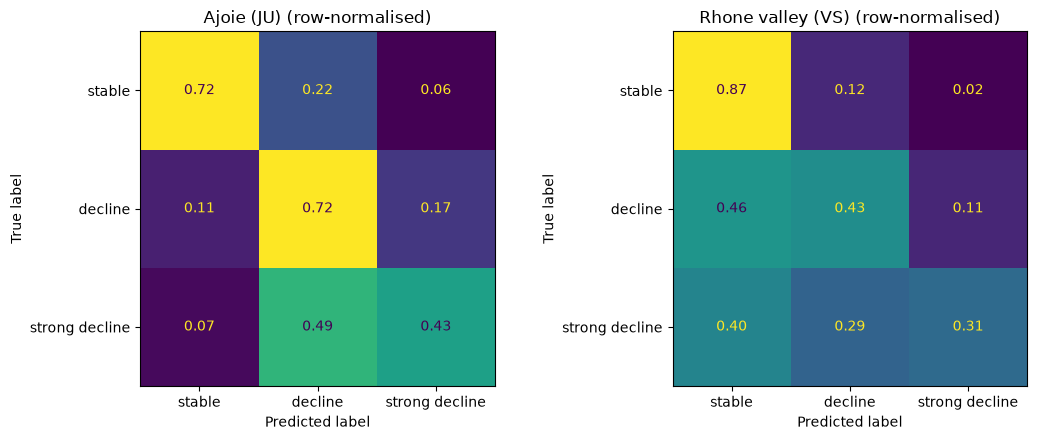

,aoi,model,n,accuracy,balanced_acc,macro_f1,qwk,mae
0,ajoie_ju,RF classifier (tuned),32123,0.713,0.625,0.462,0.309,0.339
1,ajoie_ju,"RF classifier, features standardised per AOI",32123,0.856,0.497,0.485,0.392,0.166
2,ajoie_ju,ΔNDVI-2018 threshold rule,32123,0.871,0.527,0.529,0.449,0.145
3,ajoie_ju,dummy (majority),32123,0.892,0.333,0.314,0.000,0.133
4,valais_rhone,RF classifier (tuned),38921,0.831,0.537,0.466,0.297,0.191
5,valais_rhone,"RF classifier, features standardised per AOI",38921,0.891,0.471,0.478,0.336,0.120
6,valais_rhone,ΔNDVI-2018 threshold rule,38921,0.882,0.521,0.500,0.367,0.133
7,valais_rhone,dummy (majority),38921,0.924,0.333,0.320,0.000,0.092


In [6]:
from sklearn.base import clone
# Variant against domain shift: features standardised inside each AOI (median / MAD). Uses only the
# unlabelled feature distribution of the test AOI; the proxy is standardised per AOI in the same way.
def standardise(df):
    med = df[FEATURES].median(); mad = (df[FEATURES] - med).abs().median() * 1.4826 + 1e-9
    return (df[FEATURES] - med) / mad
Z = pd.concat([standardise(g) for _, g in data.groupby("aoi")]).loc[data.index]
best_z = clone(best).fit(Z.loc[tr_idx], data.loc[tr_idx, "dmg"])

test_rows, preds, preds_z = [], {}, {}
fig, ax = plt.subplots(1, len(TEST_AOIS), figsize=(5.5 * len(TEST_AOIS), 4.5), squeeze=False)
for j, a in enumerate(TEST_AOIS):
    te = data[data.aoi == a]
    if te.empty: continue
    p = best.predict(te[FEATURES]); preds[a] = p
    test_rows.append(dict(aoi=a, model="RF classifier (tuned)", n=len(te), **metrics(te["dmg"], p)))
    preds_z[a] = best_z.predict(Z.loc[te.index])
    test_rows.append(dict(aoi=a, model="RF classifier, features standardised per AOI", n=len(te), **metrics(te["dmg"], preds_z[a])))
    if LABEL_SOURCE == "proxy":
        test_rows.append(dict(aoi=a, model="ΔNDVI-2018 threshold rule", n=len(te), **metrics(te["dmg"], te["rule_2018"])))
    test_rows.append(dict(aoi=a, model="dummy (majority)", n=len(te), **metrics(te["dmg"], np.zeros(len(te), int))))
    ConfusionMatrixDisplay(confusion_matrix(te["dmg"], p, labels=[0, 1, 2], normalize="true"),
                           display_labels=list(CLASSES.values())).plot(ax=ax[0, j], colorbar=False, values_format=".2f")
    ax[0, j].set_title(f"{su.AOIS[a]['label']} (row-normalised)")
    print(a); print(classification_report(te["dmg"], p, labels=[0, 1, 2], target_names=list(CLASSES.values()), zero_division=0))
plt.tight_layout(); plt.savefig(su.FIGS / "06_confusion_tests.png", dpi=150); plt.show()
test_tbl = pd.DataFrame(test_rows).round(3)
test_tbl.to_csv(su.TABLES / "06_test_metrics.csv", index=False)
test_tbl

## 6 · Feature importance
Permutation importance on a random sample of Ajoie test units (macro-F1 drop). For comparison: in HETRES the NDVI change 2018→2019, mean NDVI and variability measures ranked highest.

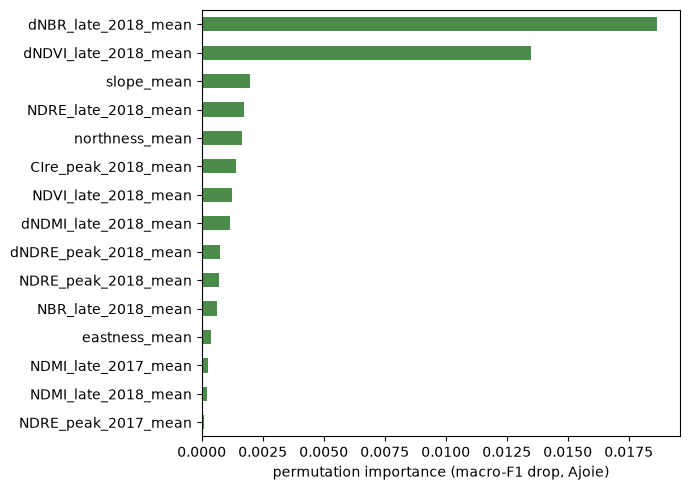

dNBR_late_2018_mean     0.0187
dNDVI_late_2018_mean    0.0135
slope_mean              0.0020
NDRE_late_2018_mean     0.0017
northness_mean          0.0017
CIre_peak_2018_mean     0.0014
NDVI_late_2018_mean     0.0012
dNDMI_late_2018_mean    0.0012
dNDRE_peak_2018_mean    0.0007
NDRE_peak_2018_mean     0.0007
dtype: float64

In [7]:
te = data[data.aoi == TEST_AOIS[0]]
te_s = te.sample(n=min(15000, len(te)), random_state=SEED)
pi = permutation_importance(best, te_s[FEATURES], te_s["dmg"], n_repeats=3, scoring="f1_macro", random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
imp.round(5).to_csv(su.TABLES / "06_permutation_importance.csv", header=["macro_f1_drop"])
fig, ax = plt.subplots(figsize=(7, 5))
imp.head(15)[::-1].plot.barh(ax=ax, color="#4c8c4a"); ax.set_xlabel("permutation importance (macro-F1 drop, Ajoie)")
plt.tight_layout(); plt.savefig(su.FIGS / "06_feature_importance.png", dpi=150); plt.show()
imp.head(10).round(4)

## 7 · Area of applicability
Share of units in each test AOI that lie inside the feature space covered by the training AOI (simplified dissimilarity index, importance-weighted). Predictions outside should be treated with caution.

In [8]:
rf = best.named_steps["randomforestclassifier"]; imputer = best.named_steps["simpleimputer"]
w = rf.feature_importances_ / rf.feature_importances_.mean()
Xtr_i = imputer.transform(Xtr)
aoa = {}
for a in TEST_AOIS:
    te = data[data.aoi == a]
    if te.empty: continue
    di, thr = su.dissimilarity_index(Xtr_i, imputer.transform(te[FEATURES]), weights=w)
    aoa[a] = pd.Series(di <= thr, index=te.unit_id.values)
    inside = aoa[a].values
    print(f"{a}: {inside.mean():.1%} of units inside AOA (DI threshold {thr:.2f}) | "
          f"macro-F1 inside {f1_score(te['dmg'][inside], preds[a][inside], average='macro'):.3f}, "
          f"outside {f1_score(te['dmg'][~inside], preds[a][~inside], average='macro') if (~inside).any() else float('nan'):.3f}")

ajoie_ju: 76.8% of units inside AOA (DI threshold 0.33) | macro-F1 inside 0.436, outside 0.383


valais_rhone: 30.7% of units inside AOA (DI threshold 0.33) | macro-F1 inside 0.394, outside 0.473


## 8 · Prediction maps
Predicted class per canopy unit, rasterised to the 10 m grid for plotting. Grey = units outside the area of applicability.

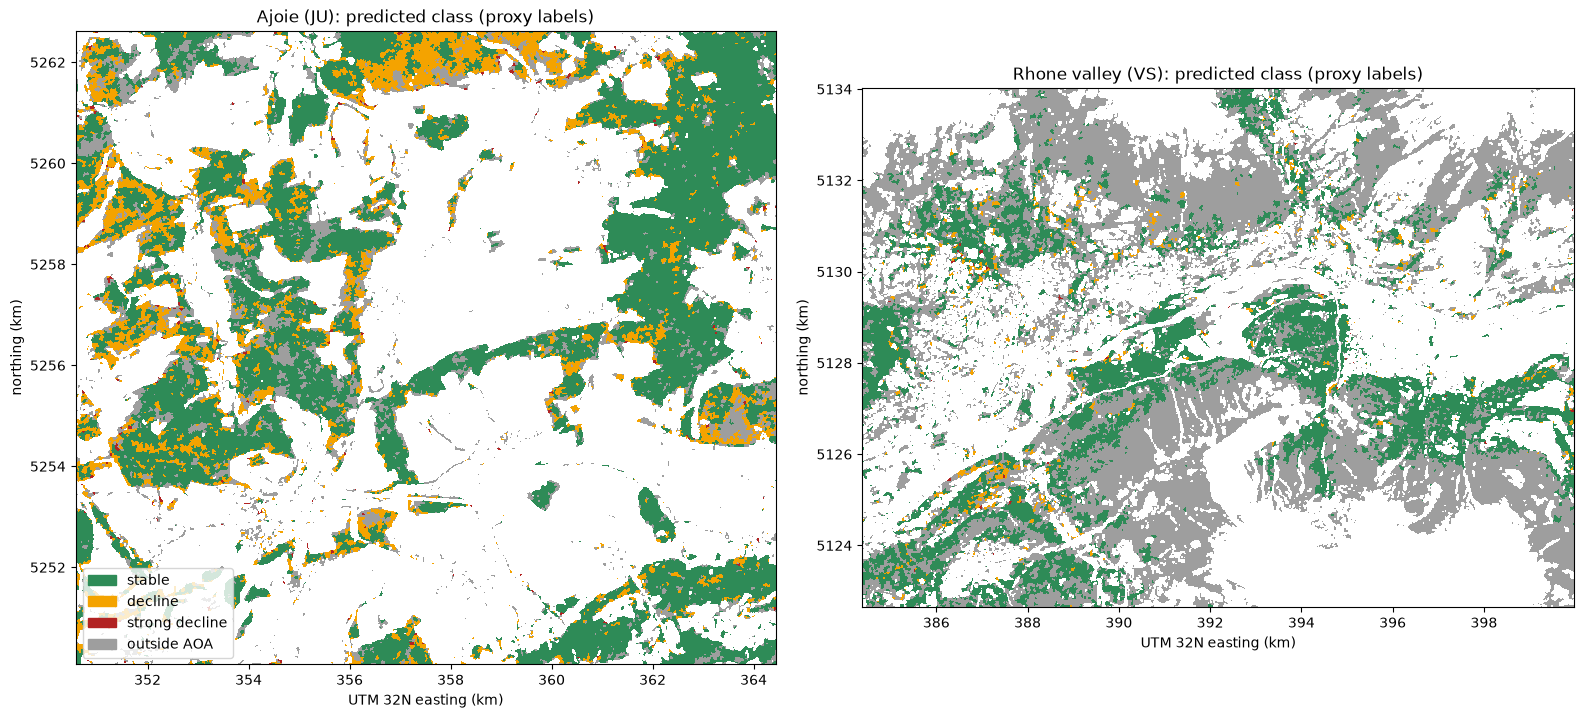

In [9]:
from rasterio import features as rfeat
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
cols = ["#2e8b57", "#f4a300", "#b22222", "#9e9e9e"]
fig, ax = plt.subplots(1, len(TEST_AOIS), figsize=(8 * len(TEST_AOIS), 7), squeeze=False)
for j, a in enumerate(TEST_AOIS):
    te = data[data.aoi == a]
    if te.empty: continue
    g = units[a].merge(pd.DataFrame({"unit_id": te.unit_id.values, "pred": preds[a], "proxy": te["dmg"].values,
                                     "inside_aoa": aoa[a].values}), on="unit_id")
    g.to_file(su.PROC / f"{a}_prediction.gpkg", driver="GPKG")
    tr_, wd, ht, xs, ys = su.aoi_grid(a)
    val = np.where(g.inside_aoa, g.pred, 3) + 1
    ras = rfeat.rasterize(zip(g.geometry, val), out_shape=(ht, wd), transform=tr_, fill=0).astype(float)
    ras[ras == 0] = np.nan
    ext = [xs[0] / 1e3, xs[-1] / 1e3, ys[-1] / 1e3, ys[0] / 1e3]
    ax[0, j].imshow(ras - 1, cmap=ListedColormap(cols), vmin=-0.5, vmax=3.5, extent=ext, interpolation="nearest")
    ax[0, j].set_title(f"{su.AOIS[a]['label']}: predicted class ({LABEL_SOURCE} labels)")
    ax[0, j].set_xlabel("UTM 32N easting (km)"); ax[0, j].set_ylabel("northing (km)")
ax[0, 0].legend(handles=[Patch(color=cols[k], label=v) for k, v in CLASSES.items()] + [Patch(color=cols[3], label="outside AOA")],
                loc="lower left", frameon=True)
plt.tight_layout(); plt.savefig(su.FIGS / "06_prediction_maps.png", dpi=150); plt.show()

## 9 · Save model and metrics

In [10]:
joblib.dump(dict(model=best, features=FEATURES, classes=CLASSES, label_source=LABEL_SOURCE), su.PROC / "rf_model.joblib")
out = dict(label_source=LABEL_SOURCE, target=TARGET if LABEL_SOURCE == "proxy" else "damage_class",
           feature_years=list(FEATURE_YEARS), n_features=len(FEATURES), n_train=len(tr),
           best_params={k: str(v) for k, v in search.best_params_.items()},
           cv=cv_tbl.to_dict("records"), test=test_tbl.to_dict("records"),
           aoa_inside={a: float(s.mean()) for a, s in aoa.items()})
(su.TABLES / "06_metrics.json").write_text(json.dumps(out, indent=2, default=float))
print("saved model + metrics; label source =", LABEL_SOURCE)

saved model + metrics; label source = proxy


## Interpretation (run of 14 Nov 2026, proxy labels)
- **The model learns something, but not more than a one-line rule.** Under spatial block CV in the Fricktal the Random Forest reaches macro-F1 0.52 (majority baseline 0.32). The rule "same threshold on the 2018 NDVI change" reaches 0.53 without any fitting.
- **Random splits are optimistic, here only slightly.** Random 5-fold gives macro-F1 0.548, block CV 0.523 (kappa 0.42 vs 0.39). The gap is small because the features are unit means and the blocks are large; it would be larger with crown-level labels clustered in a few stands.
- **Transfer to the Ajoie loses performance.** Trained in the Fricktal, the Random Forest scores macro-F1 0.46 in the Ajoie and over-predicts decline (recall 0.72 for *decline*, precision 0.22). The drought signal in 2018 was stronger in the Ajoie, so absolute feature values shift between regions. Standardising the features inside each AOI raises macro-F1 to 0.49 and kappa from 0.31 to 0.39, still below the threshold rule (0.53, kappa 0.45).
- **Area of applicability.** 77 % of the Ajoie units and only 31 % of the Rhone-valley units lie inside the feature space of the training region. The Valais is a different forest type and the model should not be applied there.
- **Most important features** in the Ajoie: the 2018 change in NBR and NDVI (late window). Terrain adds little.
- **Take-away.** Next-year spectral decline is only weakly predictable from the drought-year image at the scale of 0.16 ha units (kappa below 0.5 for every model). This says nothing yet about how well tree health can be mapped; that needs field labels.

## Limitations and next steps
- **Labels** are the bottleneck. The proxy measures NDVI decline, not forester-assessed health. With field labels from the Canton of Jura or WSL, rerun the notebook unchanged.
- The forest mask (ESA WorldCover) is not beech-specific, so the Fricktal and especially the Valais contain other species. A species or mixture mask is needed before interpreting class-wise results.
- At 10 m a canopy unit is a small group of trees, not a single crown; mixed units (healthy next to dead crown) are a systematic source of error that high-resolution RGB+NIR data would remove.
- Sentinel-2 features capture canopy greenness and moisture; HETRES also used LiDAR structure and 3 cm imagery.
- Next: the same target as a continuous regression and a U-Net (notebook 08), embeddings as alternative features (notebook 08).

## References
- Breiman, L. (2001): Random forests. *Machine Learning* 45, 5–32.
- Pedregosa, F. et al. (2011): Scikit-learn: machine learning in Python. *JMLR* 12, 2825–2830.
- Roberts, D.R. et al. (2017): Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography* 40, 913–929.
- Ploton, P. et al. (2020): Spatial validation reveals poor predictive performance of large-scale ecological mapping models. *Nature Communications* 11, 4540.
- Meyer, H., Pebesma, E. (2021): Predicting into unknown space? Estimating the area of applicability of spatial prediction models. *Methods in Ecology and Evolution* 12, 1620–1633.
- swisstopo / STDL: CLASSIFY – Gesundheitsgrad von Buchen (PROJ-HETRES; Random Forest, 70/30 split, field ground truth by cantonal foresters). https://tech.stdl.ch/PROJ-HETRES/